# Low-Vol Portfolio

## Table of Contents
[1. Equity and Stock Selection](#screener)

[2. Ranking Stock Selection](#ranking)

[3. GMV Portfolio Construction](#gmv)

[4. Backtest and Performance](#backtest)

[5. Benchmark and Out of Sample Testing](#benchmarks)

[6. Conclusions and Limitations](#conclusion)


<a id='screener'></a>
## 1. Equity and Stock Selection

In [26]:
import yfinance as yf
import datetime as dt
import pandas as pd
import numpy as np
import edhec_risk_kit_206 as erk

from yfinance import EquityQuery

In [27]:
# the yfinance screener function loses key fundamental infomration, this function gets important information for each stock selected by the screener.

from concurrent.futures import ThreadPoolExecutor

def append_fundamentals(df, symbol_col='symbol', max_workers=8):
    """
    Takes a dataframe with a ticker symbol column, fetches beta, ROE,
    and current ratio for each symbol via Ticker.info, and returns the
    dataframe with those three columns appended.
    """
    def fetch(ticker):
        info = yf.Ticker(ticker).info
        return {
            symbol_col: ticker,
            'beta': info.get('beta'),
            'returnOnEquity': info.get('returnOnEquity'),
            'currentRatio': info.get('currentRatio'),
            'sector': info.get('sector'),
        }

    with ThreadPoolExecutor(max_workers=max_workers) as ex:
        results = list(ex.map(fetch, df[symbol_col].tolist()))

    df_extra = pd.DataFrame(results)

    missing = df_extra.isna().sum()
    if missing.any():
        print("Missing values per field:\n", missing)

    return df.merge(df_extra, on=symbol_col, how='left')

In [28]:
# market cap returned was in the local currency which meant lots of Japanese companies got through unintentionally, this lets me see the true size of the company.

def get_fx_to_gbp(currencies):
    """
    Returns a dict mapping currency code -> rate to convert 1 unit of
    that currency into GBP. GBP itself maps to 1.0.
    """
    rates = {'GBP': 1.0}
    for ccy in set(currencies) - {'GBP'}:
        pair = f"{ccy}GBP=X"
        try:
            hist = yf.Ticker(pair).history(period='1d')
            rates[ccy] = hist['Close'].iloc[-1]
        except Exception as e:
            print(f"Couldn't fetch rate for {pair}: {e}")
            rates[ccy] = None
    return rates


def add_market_cap_gbp(df, currency_col='currency', market_cap_col='marketCap'):
    rates = get_fx_to_gbp(df[currency_col].unique())
    df = df.copy()
    df['fxRateToGBP'] = df[currency_col].map(rates)
    df['marketCapGBP'] = df[market_cap_col] * df['fxRateToGBP']
    return df

In [29]:
# countries that I want to select the stocks from
developed_regions = ['us', 'gb', 'de', 'fr', 'jp']

# filter stocks from the above countries for fundamentals that suggest strong ROE (>15%), well priced (<25 P/E), and low vol (<0.75 Beta)
query = EquityQuery('and', [
    EquityQuery('is-in', ['region'] + developed_regions),
    EquityQuery('gt', ['intradaymarketcap', 50_000_000_000]),
    EquityQuery('gt', ['avgdailyvol3m', 500000]),
    EquityQuery('gt', ['returnonequity.lasttwelvemonths', 10]),
    EquityQuery('gt', ['peratio.lasttwelvemonths', 0]),
    EquityQuery('lt', ['peratio.lasttwelvemonths', 25]),
    EquityQuery('lt', ['beta', 0.75]),
    EquityQuery('gt', ['netincomemargin.lasttwelvemonths', 8])
])

response = yf.screen(query, size=250, sortField = 'intradaymarketcap', sortAsc = False)
# turn the response from a jumbled mess into a dataframe
df_raw = pd.DataFrame(response['quotes'])
print(f"Returned {len(df_raw)} of {response.get('total', '?')} total matches")

df_new = append_fundamentals(df_raw)
df_new_mkt = add_market_cap_gbp(df_new)

df_final= df_new_mkt[['currency', 'shortName', 'symbol', 'trailingPE',
              'beta', 'returnOnEquity', 'currentRatio', 'marketCapGBP', 'sector']]
df_final

Returned 217 of 217 total matches
Missing values per field:
 symbol             0
beta              22
returnOnEquity    14
currentRatio      33
sector            14
dtype: int64


,currency,shortName,symbol,trailingPE,beta,returnOnEquity,currentRatio,marketCapGBP,sector
0,JPY,TOYOTA MOTOR CORP,7203.T,8.756901,0.375,0.12404,1.169,1.719640e+11,Consumer Cyclical
1,GBp,SHELL PLC ORD EUR0.07,SHEL.L,12.097632,-0.192,0.14341,1.435,2.322432e+11,Energy
2,GBp,Shell PLC,SHELL.XC,12.085798,-0.192,0.14341,1.435,2.292341e+11,Energy
3,GBp,HSBC Holdings PLC,HSBAL.XC,11.364036,0.580,0.14219,NaN,2.227116e+11,Financial Services
4,GBp,HSBC HOLDINGS PLC ORD $0.50 (UK,HSBA.L,11.343856,0.580,0.14219,NaN,2.211364e+11,Financial Services
...,...,...,...,...,...,...,...,...,...
212,GBp,ENQUEST PLC ORD 5P,ENQ.L,6.300000,-0.006,0.32854,0.636,5.862406e+08,Energy
213,USD,Devon Energy Corporation,DVN,11.169934,0.536,0.11522,0.717,4.233215e+10,Energy
214,GBp,JAMES HALSTEAD PLC ORD 5P,JHD.L,14.959000,0.294,0.19382,3.874,5.606189e+08,Industrials
215,GBp,GRESHAM HOUSE ENERGY STORAGE FU,GRID.L,3.936667,NaN,NaN,NaN,5.376518e+08,None


In [30]:
# download dataframe to excel sheet so I can easily select the remaining stocks
data = pd.DataFrame(df_final)
data.to_csv('screened_stocks_less_200.csv', index=False)

In [31]:
#
def filter(dataframe):
    df_filtered = dataframe[dataframe['marketCapGBP'] > 50e9].copy()
    df_filtered = df_filtered.dropna(subset=['returnOnEquity', 'trailingPE'])
    df_filtered = df_filtered[df_filtered['trailingPE'] > 0]
    return df_filtered

In [32]:
df_filter = filter(df_final)
df_filter

,currency,shortName,symbol,trailingPE,beta,returnOnEquity,currentRatio,marketCapGBP,sector
0,JPY,TOYOTA MOTOR CORP,7203.T,8.756901,0.375,0.12404,1.169,1.719640e+11,Consumer Cyclical
1,GBp,SHELL PLC ORD EUR0.07,SHEL.L,12.097632,-0.192,0.14341,1.435,2.322432e+11,Energy
2,GBp,Shell PLC,SHELL.XC,12.085798,-0.192,0.14341,1.435,2.292341e+11,Energy
3,GBp,HSBC Holdings PLC,HSBAL.XC,11.364036,0.580,0.14219,NaN,2.227116e+11,Financial Services
4,GBp,HSBC HOLDINGS PLC ORD $0.50 (UK,HSBA.L,11.343856,0.580,0.14219,NaN,2.211364e+11,Financial Services
...,...,...,...,...,...,...,...,...,...
193,USD,Comcast Corporation,CMCSA,6.825949,0.669,0.11432,0.821,5.749312e+10,Communication Services
195,USD,"Kinder Morgan, Inc.",KMI,20.716051,0.583,0.11428,0.670,5.611720e+10,Energy
196,USD,Manulife Financial Corporation,MFC,16.764044,0.738,0.13313,29.532,5.557990e+10,Financial Services
199,USD,"America Movil, S.A.B. de C.V.",AMX,13.912790,0.227,0.20977,0.748,5.363289e+10,Communication Services


<a id='ranking'></a>
## 2. Ranking Stock Selection

In [33]:
def rank_quality_lowvol(df, symbol_col='symbol', max_workers=8):
    """
    Fetches returnOnAssets and returnOnEquity from Ticker.info, and computes
    annualized volatility from 2 years of price history, for each symbol.
    Drops stocks missing any of the three inputs, then ranks equally across
    all three (higher ROA/ROE = better, lower volatility = better).
    """
    def fetch(ticker):
        try:
            t = yf.Ticker(ticker)
            info = t.info
            hist = t.history(period='2y')

            volatility = None
            if not hist.empty and len(hist) > 1:
                daily_returns = hist['Close'].pct_change().dropna()
                volatility = daily_returns.std() * (252 ** 0.5)  # annualized

            return {
                symbol_col: ticker,
                'name': info.get('shortName'),
                'currency': info.get('currency'),
                'returnOnAssets': info.get('returnOnAssets'),
                'returnOnEquity': info.get('returnOnEquity'),
                'volatility': volatility,
                'sector': info.get('sector'),
            }
        except Exception as e:
            print(f"Failed for {ticker}: {e}")
            return {symbol_col: ticker}

    with ThreadPoolExecutor(max_workers=max_workers) as ex:
        results = list(ex.map(fetch, df[symbol_col].tolist()))

    df_raw = pd.DataFrame(results)

    # Clear out stocks missing any required field
    required = ['returnOnAssets', 'returnOnEquity', 'volatility']
    before = len(df_raw)
    df_clean = df_raw.dropna(subset=required).copy()
    after = len(df_clean)
    print(f"Dropped {before - after} of {before} stocks missing required data")

    # Rank each metric as a percentile (0-1, higher = better)
    df_clean['roa_rank'] = df_clean['returnOnAssets'].rank(pct=True)
    df_clean['roe_rank'] = df_clean['returnOnEquity'].rank(pct=True)
    df_clean['vol_rank'] = 1 - df_clean['volatility'].rank(pct=True)  # lower vol = better

    # Equal-weighted composite
    df_clean['composite_score'] = (df_clean['roa_rank'] + df_clean['vol_rank']) / 2

    df_ranked = df_clean.sort_values('composite_score', ascending=False)

    return df_ranked[[symbol_col, 'name', 'currency', 'returnOnAssets', 'returnOnEquity', 'volatility',
                       'roa_rank', 'roe_rank', 'vol_rank', 'composite_score', 'sector']]

In [34]:
df_rank = rank_quality_lowvol(df_filter)
df_rank

Dropped 0 of 69 stocks missing required data


,symbol,name,currency,returnOnAssets,returnOnEquity,volatility,roa_rank,roe_rank,vol_rank,composite_score,sector
18,PG,Procter & Gamble Company (The),USD,0.10492,0.29609,0.197728,0.869565,0.797101,0.927536,0.898551,Consumer Defensive
8,ULVR.L,UNILEVER PLC ORD 3.5P,GBp,0.08287,0.31869,0.203087,0.760870,0.847826,0.898551,0.829710,Consumer Defensive
26,PEP,"Pepsico, Inc.",USD,0.09017,0.52187,0.219529,0.811594,0.913043,0.826087,0.818841,Consumer Defensive
36,UL,Unilever PLC,USD,0.08287,0.31869,0.220534,0.760870,0.847826,0.797101,0.778986,Consumer Defensive
6,2914.T,JAPAN TOBACCO INC,JPY,0.07413,0.14298,0.210653,0.666667,0.391304,0.855072,0.760870,Consumer Defensive
...,...,...,...,...,...,...,...,...,...,...,...
0,7203.T,TOYOTA MOTOR CORP,JPY,0.02339,0.12404,0.328577,0.202899,0.159420,0.231884,0.217391,Consumer Cyclical
9,BATSL.XC,British American Tobacco PLC,GBp,0.05119,0.13424,70.172969,0.376812,0.260870,0.000000,0.188406,Consumer Defensive
59,ITUB,Itau Unibanco Banco Holding SA,USD,0.01577,0.21476,0.357674,0.144928,0.666667,0.159420,0.152174,Financial Services
44,MFG,"Mizuho Financial Group, Inc. Sp",USD,0.00476,0.12492,0.334620,0.021739,0.181159,0.202899,0.112319,Financial Services


In [35]:
data_ranked = pd.DataFrame(df_rank)
data_ranked.to_csv('ranked_companies.csv', index=False)

In [36]:
# this demonstrates the severe lack of tech companies which dominate a large share of modern market indicies. Below there is only three companies along with copies of IBM and Sage.
df_tech = df_rank[df_rank['sector'] == 'Technology']
df_tech

,symbol,name,currency,returnOnAssets,returnOnEquity,volatility,roa_rank,roe_rank,vol_rank,composite_score,sector
21,IBM,International Business Machines,USD,0.05328,0.34769,0.404035,0.405797,0.884058,0.101449,0.253623,Technology


### Looking through the exported list and highlighting potential companies in different sectors, it's clear that technology has been heavily filtered out of the list as a result of PE filters as well as some other sectors.

In [37]:
developed_regions = ['us', 'gb', 'de', 'fr']
sectors_growth = ['Technology', 'Industrials']

# filter stocks from the above countries for fundamentals that suggest strong ROE (>15%), well priced (<25 P/E), and low vol (<0.75 Beta)
query_tech = EquityQuery('and', [
    EquityQuery('is-in', ['region'] + developed_regions),
    EquityQuery('is-in', ['sector'] + sectors_growth),
    EquityQuery('gt', ['intradaymarketcap', 50_000_000_000]),
    EquityQuery('gt', ['avgdailyvol3m', 500000]),
    EquityQuery('gt', ['returnonequity.lasttwelvemonths', 10]),
    EquityQuery('gt', ['peratio.lasttwelvemonths', 0]),
    EquityQuery('lt', ['peratio.lasttwelvemonths', 50]),
    EquityQuery('lt', ['beta', 1.1]),
    EquityQuery('gt', ['netincomemargin.lasttwelvemonths', 8])
])

response_tech = yf.screen(query_tech, size=250, sortField = 'intradaymarketcap', sortAsc = False)
# turn the response from a jumbled mess into a dataframe
df_raw_tech = pd.DataFrame(response_tech['quotes'])
print(f"Returned {len(df_raw_tech)} of {response.get('total', '?')} total matches")

df_new_tech = append_fundamentals(df_raw_tech)
df_new_mkt = add_market_cap_gbp(df_new_tech)

df_final_tech = df_new_mkt[['currency', 'shortName', 'symbol', 'trailingPE',
              'beta', 'returnOnEquity', 'currentRatio', 'marketCapGBP', 'sector']]
df_final_tech

Returned 42 of 217 total matches
Missing values per field:
 symbol            0
beta              2
returnOnEquity    0
currentRatio      0
sector            0
dtype: int64


,currency,shortName,symbol,trailingPE,beta,returnOnEquity,currentRatio,marketCapGBP,sector
0,GBp,RELX PLC,RELL.XC,23.272000,0.281000,1.31864,0.449,5.202229e+10,Industrials
1,GBp,RELX PLC ORD 14 51/116P,REL.L,23.231983,0.281000,1.31864,0.449,5.040277e+10,Industrials
2,USD,Apple Inc.,AAPL,39.430042,1.069000,1.48751,1.003,3.766499e+12,Technology
3,USD,Microsoft Corporation,MSFT,29.582730,1.099000,0.34039,1.230,2.959685e+12,Technology
4,GBp,EXPERIAN PLC ORD USD0.10,EXPN.L,23.795082,0.899000,0.28258,0.854,2.542790e+10,Industrials
5,GBp,THE SAGE GROUP PLC ORD 1 4/77P,SGE.L,28.499998,0.349000,0.75564,0.624,1.026625e+10,Technology
6,SEK,ATLAS COPCO AB ATLAS COPCO SERI,0XXV.IL,30.617977,0.894576,0.34389,1.344,6.975111e+10,Industrials
7,SEK,ATLAS COPCO AB ATLAS COPCO A OR,0XXT.IL,34.934456,0.894576,0.34389,1.344,6.939909e+10,Industrials
8,GBp,IMI PLC ORD 28 4/7P,IMI.L,21.441175,1.012000,0.35782,1.305,6.847482e+09,Industrials
9,GBp,WEIR PLC ORD 12.5P,WEIR.L,26.000000,1.089000,0.13930,2.550,6.817413e+09,Industrials


In [38]:
df_rank_tech = rank_quality_lowvol(df_final_tech)
df_rank_tech

Dropped 0 of 42 stocks missing required data


,symbol,name,currency,returnOnAssets,returnOnEquity,volatility,roa_rank,roe_rank,vol_rank,composite_score,sector
30,ITW,Illinois Tool Works Inc.,USD,0.17127,1.01653,0.219240,0.928571,0.904762,0.952381,0.940476,Industrials
36,FAST,Fastenal Company,USD,0.21965,0.35262,0.247117,0.952381,0.642857,0.761905,0.857143,Industrials
28,CTAS,Cintas Corporation,USD,0.16655,0.41375,0.246576,0.904762,0.714286,0.785714,0.845238,Industrials
8,IMI.L,IMI PLC ORD 28 4/7P,GBp,0.12297,0.35782,0.239746,0.714286,0.666667,0.833333,0.773810,Industrials
29,MSI,"Motorola Solutions, Inc.",USD,0.11250,0.91567,0.245186,0.666667,0.880952,0.809524,0.738095,Technology
2,AAPL,Apple Inc.,USD,0.27082,1.48751,0.287109,1.000000,1.000000,0.476190,0.738095,Technology
38,JHD.L,JAMES HALSTEAD PLC ORD 5P,GBp,0.11961,0.19382,0.261508,0.690476,0.285714,0.714286,0.702381,Industrials
19,UNP,Union Pacific Corporation,USD,0.09507,0.38747,0.231224,0.523810,0.690476,0.880952,0.702381,Industrials
32,CNI,Canadian National Railway Compa,USD,0.07722,0.22018,0.223013,0.380952,0.333333,0.928571,0.654762,Industrials
3,MSFT,Microsoft Corporation,USD,0.14088,0.34039,0.291385,0.857143,0.547619,0.452381,0.654762,Technology


In [39]:
data_tech = pd.DataFrame(df_rank_tech)
data_tech.to_csv('tech_ranked_companies.csv', index=False)

In [40]:
developed_regions = ['us', 'gb', 'de', 'fr']
sectors_growth_tech = ['Technology']

# filter stocks from the above countries for fundamentals that suggest strong ROE (>15%), well priced (<25 P/E), and low vol (<0.75 Beta)
query_tech = EquityQuery('and', [
    EquityQuery('is-in', ['region'] + developed_regions),
    EquityQuery('eq', ['sector', 'Technology']),
    EquityQuery('gt', ['intradaymarketcap', 50_000_000_000]),
    EquityQuery('gt', ['avgdailyvol3m', 500000]),
    EquityQuery('gt', ['returnonequity.lasttwelvemonths', 10]),
    EquityQuery('gt', ['peratio.lasttwelvemonths', 0]),
    EquityQuery('lt', ['peratio.lasttwelvemonths', 50]),
    EquityQuery('gt', ['netincomemargin.lasttwelvemonths', 8])
])

response_tech_g = yf.screen(query_tech, size=250, sortField = 'intradaymarketcap', sortAsc = False)
# turn the response from a jumbled mess into a dataframe
df_raw_tech_g = pd.DataFrame(response_tech_g['quotes'])
print(f"Returned {len(df_raw_tech_g)} of {response_tech_g.get('total', '?')} total matches")

df_new_tech_g = append_fundamentals(df_raw_tech_g)
df_new_mkt_g = add_market_cap_gbp(df_new_tech_g)

df_final_tech_g = df_new_mkt_g[['currency', 'shortName', 'symbol', 'trailingPE',
              'beta', 'returnOnEquity', 'currentRatio', 'marketCapGBP', 'sector']]
df_rank_tech_g = rank_quality_lowvol(df_final_tech_g)
df_rank_tech_g_sort_vol = df_rank_tech_g.sort_values('volatility', ascending=True)
df_rank_tech_g_sort_vol

Returned 41 of 41 total matches
Missing values per field:
 symbol            0
beta              4
returnOnEquity    0
currentRatio      0
sector            0
dtype: int64
Dropped 0 of 41 stocks missing required data


,symbol,name,currency,returnOnAssets,returnOnEquity,volatility,roa_rank,roe_rank,vol_rank,composite_score,sector
35,MSI,"Motorola Solutions, Inc.",USD,0.11250,0.91567,0.245186,0.487805,0.829268,0.975610,0.731707,Technology
2,AAPL,Apple Inc.,USD,0.27082,1.48751,0.287109,0.853659,0.975610,0.951220,0.902439,Technology
3,MSFT,Microsoft Corporation,USD,0.14088,0.34039,0.291385,0.560976,0.390244,0.926829,0.743902,Technology
13,CSCO,"Cisco Systems, Inc.",USD,0.07978,0.27319,0.297335,0.292683,0.317073,0.902439,0.597561,Technology
39,ALFA.L,ALFA FINANCIAL SOFTWARE HOLDING,GBp,0.25563,0.53839,0.303352,0.804878,0.585366,0.878049,0.841463,Technology
14,0O87.IL,TELEFONAKTIEBOLAGET LM ERICSSON,SEK,0.03740,-0.19255,0.306583,0.073171,0.024390,0.853659,0.463415,Technology
8,SGE.L,THE SAGE GROUP PLC ORD 1 4/77P,GBp,0.09533,0.75564,0.307400,0.341463,0.731707,0.829268,0.585366,Technology
37,TEL,TE Connectivity plc,USD,0.09717,0.24610,0.326431,0.365854,0.243902,0.804878,0.585366,Technology
9,WISE.L,WISE GROUP PLC CLS A ORD USD0.0,GBp,0.02412,0.27232,0.334013,0.048780,0.292683,0.780488,0.414634,Technology
18,SAP,SAP SE,USD,0.09906,0.18178,0.338124,0.402439,0.134146,0.756098,0.579268,Technology


In [41]:
data_tech_g = pd.DataFrame(df_rank_tech_g_sort_vol)
data_tech_g.to_csv('tech_g_ranked_companies.csv', index=False)

<a id='gmv'></a>
## 3. GMV Portfolio Construction

In [42]:
# lets download the prices for these stocks, then find out returns, calculate the covariance matrix, then input the values into shrinkage gmv calculator.
tickers_pf = ['IMI.L', 
              'AAPL', 
              'AME', 
              'WM', 
              'SAF.PA', 
              '0NW4.IL', 
              'PG', 
              '0QOK.IL', 
              'PEP', 
              'BRK-B', 
              'NVS', 
              'SHELL.XC', 
              'TTE.PA', 
              'LMT', 
              'AZN', 
              'CS.PA', 
              'AEM', 
              'NEM', 
              'T', 
              'TMUS',
              'HSBAL.XC', 
              'IBM',
              '7203.T', 
              'MSFT', 
              'MSI', 
              'CSCO', 
              'ADP']
names = {tkr: yf.Ticker(tkr).info.get('shortName') for tkr in tickers_pf}
names

{'IMI.L': 'IMI PLC ORD 28 4/7P',
 'AAPL': 'Apple Inc.',
 'AME': 'AMETEK, Inc.',
 'WM': 'Waste Management, Inc.',
 'SAF.PA': 'SAFRAN',
 '0NW4.IL': 'SAP SE SAP ORD SHS',
 'PG': 'Procter & Gamble Company (The)',
 '0QOK.IL': 'ROCHE HOLDING AG ROCHE HOLDING ',
 'PEP': 'Pepsico, Inc.',
 'BRK-B': 'Berkshire Hathaway Inc. New',
 'NVS': 'Novartis AG',
 'SHELL.XC': 'Shell PLC',
 'TTE.PA': 'TOTALENERGIES',
 'LMT': 'Lockheed Martin Corporation',
 'AZN': 'AstraZeneca PLC',
 'CS.PA': 'AXA',
 'AEM': 'Agnico Eagle Mines Limited',
 'NEM': 'Newmont Corporation',
 'T': 'AT&T Inc.',
 'TMUS': 'T-Mobile US, Inc.',
 'HSBAL.XC': 'HSBC Holdings PLC',
 'IBM': 'International Business Machines',
 '7203.T': 'TOYOTA MOTOR CORP',
 'MSFT': 'Microsoft Corporation',
 'MSI': 'Motorola Solutions, Inc.',
 'CSCO': 'Cisco Systems, Inc.',
 'ADP': 'Automatic Data Processing, Inc.'}

[*********************100%***********************]  27 of 27 completed
/tmp/ipykernel_183/1285223229.py:4: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  pf_rets = prices.pct_change().dropna()


,Annualized Return,Annualized Vol,Skewness,Kurtosis,Cornish-Fisher VaR (5%),Historic CVaR (5%),Sharpe Ratio,Max Drawdown
0NW4.IL,0.11816,0.25489,-0.24458,5.46204,0.10992,0.14571,0.33631,-0.48722
0QOK.IL,0.04617,0.16543,0.53363,3.63435,0.06533,0.07640,0.09496,-0.35745
7203.T,0.11557,0.23892,0.27491,3.78883,0.09502,0.12537,0.34831,-0.39384
AAPL,0.26659,0.26505,-0.06135,2.56634,0.10467,0.12878,0.86859,-0.30462
ADP,0.14646,0.20443,-0.01844,3.54821,0.08323,0.11679,0.55424,-0.36015
AEM,0.17490,0.43112,0.55726,4.02946,0.16019,0.20618,0.32659,-0.47283
AME,0.13285,0.21406,-0.02121,3.24370,0.08904,0.11558,0.46740,-0.27624
AZN,0.10589,0.21992,0.41834,3.38867,0.08547,0.11055,0.33561,-0.26969
BRK-B,0.12077,0.17048,-0.02671,2.74420,0.07056,0.08708,0.51804,-0.24338
CS.PA,0.12882,0.25498,0.53137,9.71806,0.08646,0.15521,0.37691,-0.42872


<Axes: title={'center': 'Returns of 27 Stocks the Last 2 years'}, xlabel='Date'>

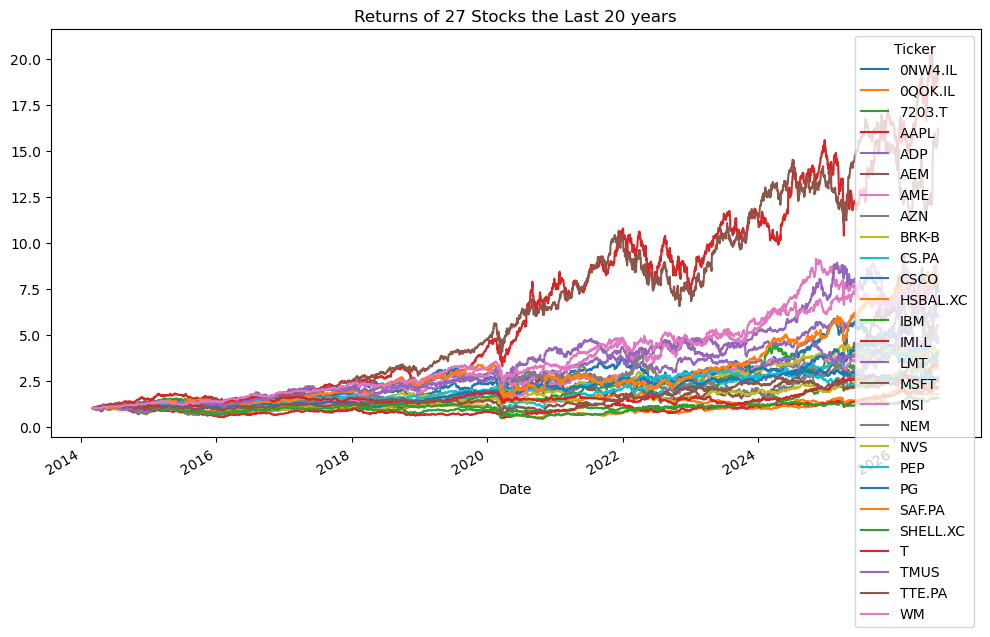

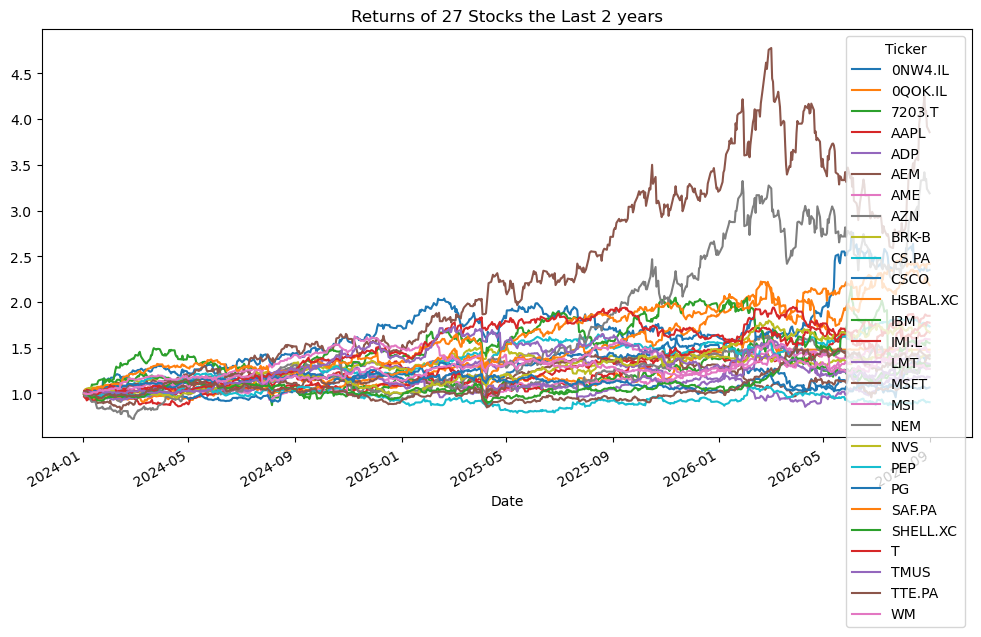

In [43]:
start_pf = '2006-09-01'
end_pf = '2026-09-01'
prices = yf.download(tickers_pf, start_pf, end_pf)['Close']
pf_rets = prices.pct_change().dropna()
pf_rets_monthly = ( 1 + pf_rets).resample('ME').prod() - 1
wealth = (1 + pf_rets).cumprod()
wealth.plot(figsize=(12,6), title='Returns of 27 Stocks the Last 20 years')

pf_performance = pd.DataFrame({
    ticker: pf_rets_monthly[ticker] for ticker in pf_rets_monthly.columns
})
display(erk.summary_stats(pf_performance.dropna()).round(5))

pf_rets_2y = pf_rets['2024':]
wealth_2y = (1 + pf_rets_2y).cumprod()
wealth_2y.plot(figsize=(12,6), title='Returns of 27 Stocks the Last 2 years')

In [44]:
import edhec_risk_kit_206 as erk

In [45]:
pf_cov_2y = erk.shrinkage_cov(pf_rets_2y)
pf_cov_1y = erk.shrinkage_cov(pf_rets_2y['2025':'2026'])
gmv_2y = erk.gmv(pf_cov_2y)
gmv_1y = erk.gmv(pf_cov_1y)

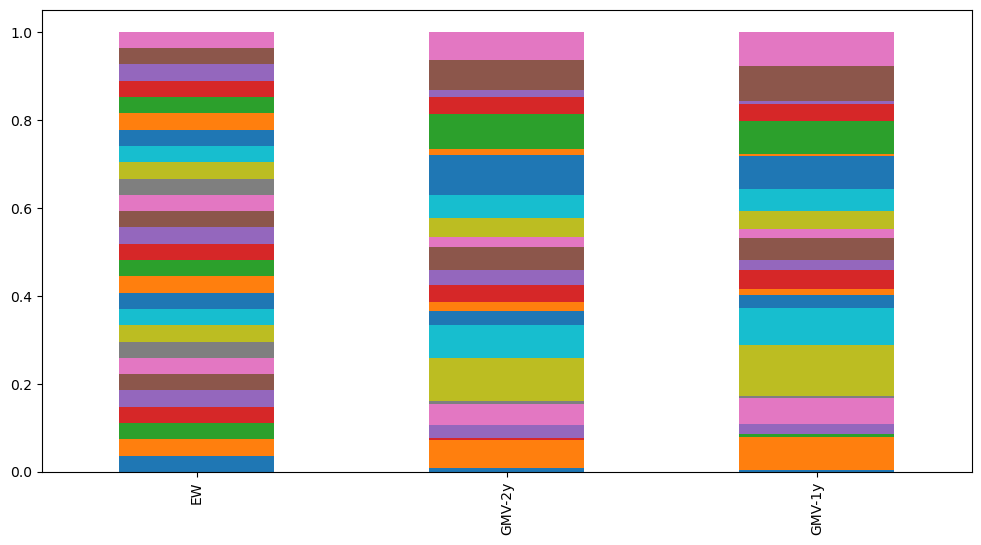

In [46]:
wts = pd.DataFrame({
    "EW": erk.weight_ew(pf_rets_2y),
    "GMV-2y": gmv_2y,
    "GMV-1y": gmv_1y,
})
wts.T.plot.bar(stacked=True, figsize=(12,6), legend=False);

In [47]:
weights_series = pd.Series(gmv_2y, index=tickers_pf)
weights_series

IMI.L       8.150675e-03
AAPL        6.380009e-02
AME         1.591810e-03
WM          3.155847e-03
SAF.PA      2.991736e-02
0NW4.IL     4.101352e-13
PG          4.661760e-02
0QOK.IL     9.012726e-03
PEP         9.758068e-02
BRK-B       7.509306e-02
NVS         2.997287e-02
SHELL.XC    2.170334e-02
TTE.PA      0.000000e+00
LMT         3.717192e-02
AZN         3.537461e-02
CS.PA       5.096265e-02
AEM         2.286700e-02
NEM         0.000000e+00
T           4.323717e-02
TMUS        5.204120e-02
HSBAL.XC    9.288850e-02
IBM         1.199284e-02
7203.T      8.005434e-02
MSFT        3.811663e-02
MSI         1.693833e-02
CSCO        6.711898e-02
ADP         6.463977e-02
dtype: float64

In [48]:
# There is too much concentration into some stocks
from scipy.optimize import minimize

def weight_gmv_bounded(cov, min_weight=None, max_weight=None):
    """
    Produces the weights of the GMV (Global Minimum Volatility) portfolio,
    with optional min/max weight bounds per asset.

    cov        : covariance matrix (DataFrame, with tickers as index/columns)
    min_weight : minimum weight per asset. Defaults to 0.0 if None.
    max_weight : maximum weight per asset. Defaults to 1.0 if None.
    """
    n = cov.shape[0]

    lb = 0.0 if min_weight is None else min_weight
    ub = 1.0 if max_weight is None else max_weight
    bounds = ((lb, ub),) * n

    init_guess = np.repeat(1/n, n)
    weights_sum_to_1 = {'type': 'eq', 'fun': lambda weights: np.sum(weights) - 1}

    def portfolio_vol(weights, cov):
        return (weights.T @ cov @ weights) ** 0.5

    def neg_sharpe(weights, riskfree_rate, er, cov):
        r = weights.T @ er
        vol = portfolio_vol(weights, cov)
        return -(r - riskfree_rate) / vol

    er = np.repeat(1, n)
    riskfree_rate = 0

    result = minimize(neg_sharpe, init_guess,
                       args=(riskfree_rate, er, cov), method='SLSQP',
                       options={'disp': False},
                       constraints=(weights_sum_to_1,),
                       bounds=bounds)

    return pd.Series(result.x, index=cov.columns if hasattr(cov, 'columns') else None)

In [49]:
n = len(tickers_pf)
ew = 1 / n
gmv_2y_bounds = weight_gmv_bounded(pf_cov_2y, min_weight=ew/3, max_weight=ew*3)

In [50]:
weights_series_b = pd.Series(gmv_2y_bounds, index=tickers_pf)
weights_series_b

IMI.L       0.031864
AAPL        0.012346
AME         0.041720
WM          0.062297
SAF.PA      0.012346
0NW4.IL     0.012346
PG          0.090053
0QOK.IL     0.063084
PEP         0.051008
BRK-B       0.094799
NVS         0.033642
SHELL.XC    0.078056
TTE.PA      0.065350
LMT         0.032750
AZN         0.012346
CS.PA       0.070706
AEM         0.012346
NEM         0.012346
T           0.035958
TMUS        0.018028
HSBAL.XC    0.017077
IBM         0.012346
7203.T      0.012346
MSFT        0.043598
MSI         0.019908
CSCO        0.024078
ADP         0.027258
dtype: float64

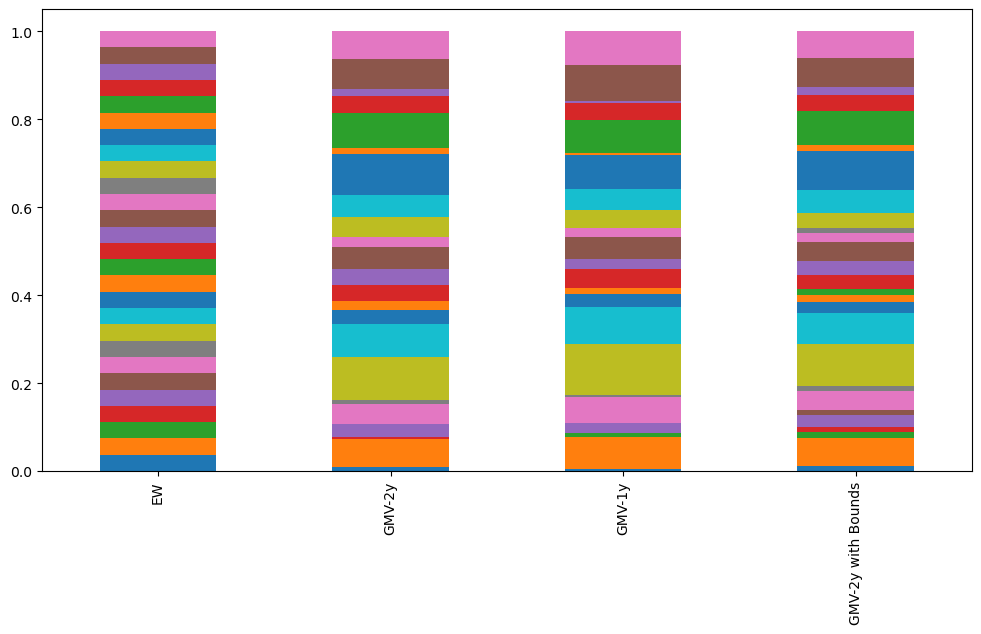

In [51]:
wts_with_bounds = pd.DataFrame({
    "EW": erk.weight_ew(pf_rets_2y),
    "GMV-2y": gmv_2y,
    "GMV-1y": gmv_1y,
    "GMV-2y with Bounds": gmv_2y_bounds,
})
wts_with_bounds.T.plot.bar(stacked=True, figsize=(12,6), legend=False);

<a id='backtest'></a>
## 4. Backtest and Performance

,Annualized Return,Annualized Vol,Skewness,Kurtosis,Cornish-Fisher VaR (5%),Historic CVaR (5%),Sharpe Ratio,Max Drawdown
EW Portfolio,0.22232,0.09361,-0.67710,3.85671,0.03096,0.04438,1.99978,-0.06250
GMB no adj,0.16464,0.08583,0.09139,3.01187,0.02639,0.03272,1.52689,-0.04997
GMV 2y Portfolio,0.16274,0.08624,-0.01636,2.71571,0.02762,0.03534,1.49807,-0.03664
GMV 1y Portfolio,0.16461,0.08580,0.01573,2.57789,0.02712,0.03338,1.52704,-0.03528
GMV Bounded Portfolio,0.17260,0.08610,-0.06263,2.72209,0.02716,0.03589,1.61208,-0.04222


<Axes: title={'center': 'GMV Portfolios'}, xlabel='Date'>

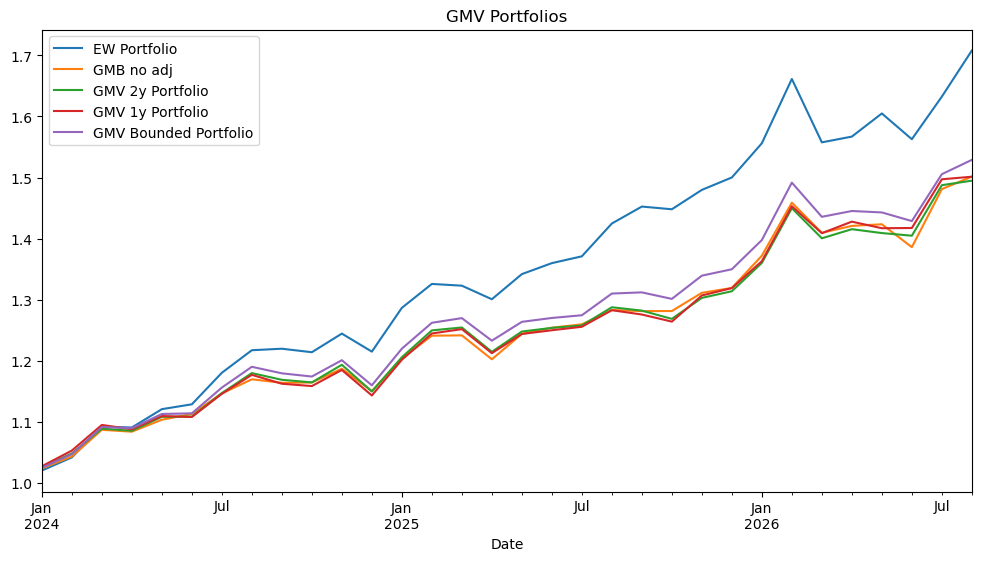

In [52]:
pf_rets_monthly = (1 + pf_rets_2y).resample('ME').prod() - 1
pf_rets_gmv_bounded = pf_rets_monthly @ gmv_2y_bounds
btr_bounded = pd.DataFrame({
    'EW Portfolio': pf_rets_monthly @ erk.weight_ew(pf_rets_2y),
    'GMB no adj': pf_rets_monthly @ erk.weight_gmv(pf_rets_2y),
    'GMV 2y Portfolio': pf_rets_monthly @ gmv_2y,
    'GMV 1y Portfolio': pf_rets_monthly @ gmv_1y,
    'GMV Bounded Portfolio': pf_rets_gmv_bounded,
})
display(erk.summary_stats(btr_bounded.dropna()).round(5))
(1 + btr_bounded).cumprod().dropna().plot(figsize=(12,6), title='GMV Portfolios')

[*********************100%***********************]  2 of 2 completed


,Annualized Return,Annualized Vol,Skewness,Kurtosis,Cornish-Fisher VaR (5%),Historic CVaR (5%),Sharpe Ratio,Max Drawdown
EW Portfolio,0.22232,0.09361,-0.67710,3.85671,0.03096,0.04438,1.99978,-0.06250
GMV Bounded Portfolio,0.17260,0.08610,-0.06263,2.72209,0.02716,0.03589,1.61208,-0.04222
USMV,0.12008,0.09003,-0.82479,3.27551,0.03778,0.05227,0.97380,-0.05660
VTI,0.20523,0.12201,-0.02789,3.19646,0.04089,0.05430,1.39790,-0.08404


<Axes: title={'center': 'Portfolio vs Benchmarks'}, xlabel='Date'>

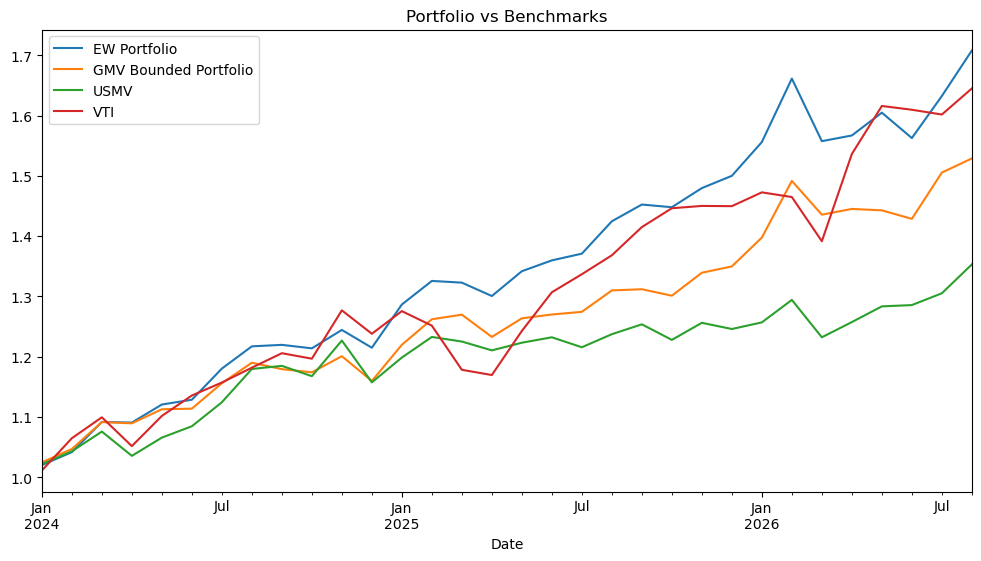

In [53]:
benchmarks = ['VTI', 'USMV']
bench_prices = yf.download(benchmarks, start_pf, end_pf)['Close']
bench_rets = bench_prices.pct_change().dropna()
bench_rets_monthly = (1 + bench_rets).resample('ME').prod() - 1

btr_full = pd.DataFrame({
    'EW Portfolio': pf_rets_monthly @ erk.weight_ew(pf_rets_2y),
    'GMV Bounded Portfolio': pf_rets_gmv_bounded,
})
btr_vs_benchmark = btr_full.join(bench_rets_monthly, how='inner')
display(erk.summary_stats(btr_vs_benchmark.dropna()).round(5))
(1 + btr_vs_benchmark).cumprod().plot(figsize=(12,6), title='Portfolio vs Benchmarks')

<a id='benchmark'></a>
## 5. Benchmark and Out of Sample Testing

In [54]:
long_prices = yf.download(tickers_pf, period='10y')['Close']
long_rets = long_prices.pct_change().dropna()
long_rets_monthly = (1 + long_rets).resample('ME').prod() - 1

medium_prices = yf.download(tickers_pf, period='5y')['Close']
medium_rets = medium_prices.pct_change().dropna()
medium_rets_monthly = (1 + medium_rets).resample('ME').prod() - 1

[*********************100%***********************]  27 of 27 completed
/tmp/ipykernel_183/4283452025.py:2: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  long_rets = long_prices.pct_change().dropna()
[*********************100%***********************]  27 of 27 completed
/tmp/ipykernel_183/4283452025.py:6: FutureWarning: The default fill_method='pad' in DataFrame.pct_change is deprecated and will be removed in a future version. Either fill in any non-leading NA values prior to calling pct_change or specify 'fill_method=None' to not fill NA values.
  medium_rets = medium_prices.pct_change().dropna()


In [55]:
long_benchmarks = ['VTI', 'USMV']
long_bench_prices = yf.download(long_benchmarks, start_pf, end_pf)['Close']
long_bench_rets = long_bench_prices.pct_change().dropna()
long_bench_rets_monthly = (1 + long_bench_rets).resample('ME').prod() - 1

medium_benchmarks = ['VTI', 'USMV']
medium_bench_prices = yf.download(medium_benchmarks, start_pf, end_pf)['Close']
medium_bench_rets = medium_bench_prices.pct_change().dropna()
medium_bench_rets_monthly = (1 + medium_bench_rets).resample('ME').prod() - 1

[*********************100%***********************]  2 of 2 completed
[*********************100%***********************]  2 of 2 completed


,Annualized Return,Annualized Vol,Skewness,Kurtosis,Cornish-Fisher VaR (5%),Historic CVaR (5%),Sharpe Ratio,Max Drawdown
EW Portfolio,0.16415,0.12379,-0.24467,4.45872,0.04654,0.07165,1.05471,-0.18566
GMV Bounded Portfolio,0.14420,0.12157,-0.03712,5.63299,0.04410,0.07077,0.91421,-0.19585
USMV,0.10782,0.12246,-0.62496,3.77988,0.05415,0.07575,0.61833,-0.19056
VTI,0.15319,0.15855,-0.46870,3.78729,0.06713,0.09609,0.75611,-0.24819


<Axes: title={'center': 'Portfolio vs Benchmarks over 10 years'}, xlabel='Date'>

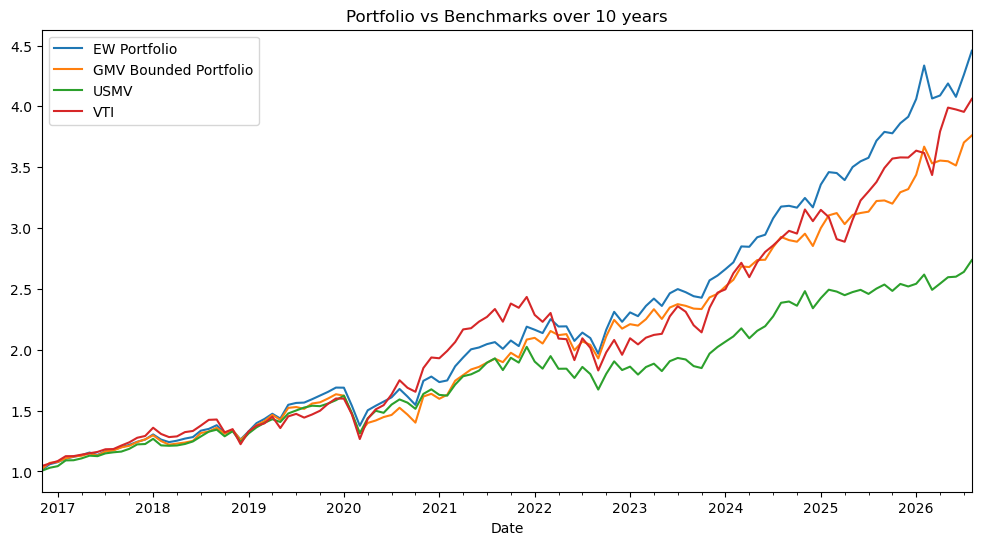

In [56]:
btr_stress = pd.DataFrame({
    'EW Portfolio': long_rets_monthly @ erk.weight_ew(pf_rets_2y),
    'GMV Bounded Portfolio': long_rets_monthly @ gmv_2y_bounds
})
btr_vs_benchmark_stress = btr_stress.join(long_bench_rets_monthly, how='inner')
display(erk.summary_stats(btr_vs_benchmark_stress.dropna()).round(5))
(1 + btr_vs_benchmark_stress).cumprod().plot(figsize=(12,6), title='Portfolio vs Benchmarks over 10 years')

,Annualized Return,Annualized Vol,Skewness,Kurtosis,Cornish-Fisher VaR (5%),Historic CVaR (5%),Sharpe Ratio,Max Drawdown
EW Portfolio,0.17128,0.11778,-0.03244,2.90081,0.04200,0.05947,1.16746,-0.12622
GMV Bounded Portfolio,0.14251,0.10894,0.10904,3.06994,0.03862,0.05159,1.00513,-0.10452
USMV,0.07446,0.12131,-0.21123,2.35736,0.05300,0.06239,0.35658,-0.17352
VTI,0.11695,0.15985,-0.23767,2.63463,0.06832,0.08864,0.52924,-0.24819


<Axes: title={'center': 'Portfolio vs Benchmarks over 5 years'}, xlabel='Date'>

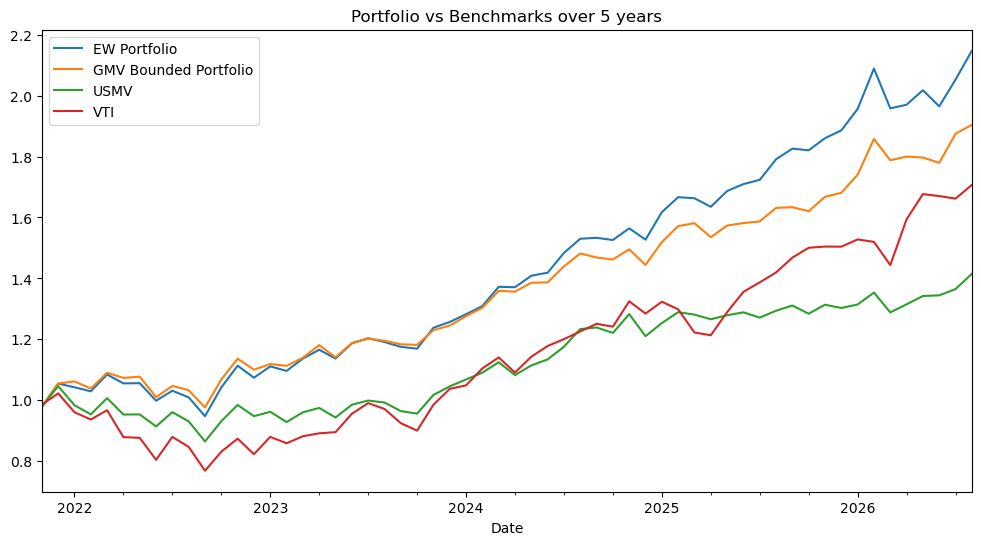

In [57]:
btr_stress = pd.DataFrame({
    'EW Portfolio': medium_rets_monthly @ erk.weight_ew(pf_rets_2y),
    'GMV Bounded Portfolio': medium_rets_monthly @ gmv_2y_bounds
})
btr_vs_benchmark_stress_5y = btr_stress.join(medium_bench_rets_monthly, how='inner')
display(erk.summary_stats(btr_vs_benchmark_stress_5y.dropna()).round(5))
(1 + btr_vs_benchmark_stress_5y).cumprod().plot(figsize=(12,6), title='Portfolio vs Benchmarks over 5 years')

<a id='conclusion'></a>
## 6. Conclusion

#### To conclude the objective was to select a group of stocks that grow steadily with lower drawdown exposure against broad equities. The equity screen found stocks that compounded well over time and matched the performance over the VTI whilst reducing volatility from 16.1% to 10.8% and shouldered drawdowns well demonstrating a 10.5% drop versus 24.8% from the VTI. Sharpe ratio was also much better largely due to less volatility. That made it successful in its objective in finding a set of stocks that can reliably get steady returns whilst shielding the investor from downturns and market volatility.

#### The portfolios success can be attributed to the underlying stocks reliable cash flows, that sell consumer staples and largely own defensive assets. The techniques applied to the GMV portfolio also were successful, improving the performance of the portfolio in annual return whilst maintaining the volatility and drawdown performance of the initial GMV portfolio. Although the EW portfolio still had the highest Sharpe ratio, it had worse vol and draw down results and this was because it had much more exposure to the more volatile tech stocks that have performed really well over the lookback periods. This demonstrates the tests lookback and survivorship bias as I was the one picking the stocks out of last batch and I would tend to lean on stocks that I believe would still do well as a result of past success. Moreover the some outliers in the stocks picked have had obscene returns that would drag the returns up such as 'Apple' and 'Microsoft'.

#### From looking at the out of sample ten year and five year returns, shrinking and giving bounds to the weights of the stocks has proven to create a portfolio that performs better out of sample due to less sample risk and concentration risk that you get from the GMV function over weighting less volatile stocks.

#### The limitations this test has is that the backtests don't rebalance the portfolio, its based off the local currencies of the stocks therefore the FX movements haven't been taken into account, survivorship bias and perhaps letting some outliers skew the average returns.

#### If I was to continue this project I would take out the outlier stocks that could skew the results, go further with the backtest that rebalances the weights of the portfolio and explore factor regressions for the drivers of return and risk and explore using machine learning for determining weights of the portfolio.

In [59]:
gmv_2y_bounds

Ticker
0NW4.IL     0.012346
0QOK.IL     0.063084
7203.T      0.012346
AAPL        0.012346
ADP         0.027258
AEM         0.012346
AME         0.041720
AZN         0.012346
BRK-B       0.094799
CS.PA       0.070706
CSCO        0.024078
HSBAL.XC    0.017077
IBM         0.012346
IMI.L       0.031864
LMT         0.032750
MSFT        0.043598
MSI         0.019908
NEM         0.012346
NVS         0.033642
PEP         0.051008
PG          0.090053
SAF.PA      0.012346
SHELL.XC    0.078056
T           0.035958
TMUS        0.018028
TTE.PA      0.065350
WM          0.062297
dtype: float64

In [62]:
weights_for_portofolio = gmv_2y_bounds.round(4)
weights_for_portofolio

Ticker
0NW4.IL     0.0123
0QOK.IL     0.0631
7203.T      0.0123
AAPL        0.0123
ADP         0.0273
AEM         0.0123
AME         0.0417
AZN         0.0123
BRK-B       0.0948
CS.PA       0.0707
CSCO        0.0241
HSBAL.XC    0.0171
IBM         0.0123
IMI.L       0.0319
LMT         0.0328
MSFT        0.0436
MSI         0.0199
NEM         0.0123
NVS         0.0336
PEP         0.0510
PG          0.0901
SAF.PA      0.0123
SHELL.XC    0.0781
T           0.0360
TMUS        0.0180
TTE.PA      0.0654
WM          0.0623
dtype: float64

In [68]:
names_of_companies = {
    t: yf.Ticker(t).info.get("shortName", t)
    for t in weights_for_portofolio.index
}
names_of_companies

{'0NW4.IL': 'SAP SE SAP ORD SHS',
 '0QOK.IL': 'ROCHE HOLDING AG ROCHE HOLDING ',
 '7203.T': 'TOYOTA MOTOR CORP',
 'AAPL': 'Apple Inc.',
 'ADP': 'Automatic Data Processing, Inc.',
 'AEM': 'Agnico Eagle Mines Limited',
 'AME': 'AMETEK, Inc.',
 'AZN': 'AstraZeneca PLC',
 'BRK-B': 'Berkshire Hathaway Inc. New',
 'CS.PA': 'AXA',
 'CSCO': 'Cisco Systems, Inc.',
 'HSBAL.XC': 'HSBC Holdings PLC',
 'IBM': 'International Business Machines',
 'IMI.L': 'IMI PLC ORD 28 4/7P',
 'LMT': 'Lockheed Martin Corporation',
 'MSFT': 'Microsoft Corporation',
 'MSI': 'Motorola Solutions, Inc.',
 'NEM': 'Newmont Corporation',
 'NVS': 'Novartis AG',
 'PEP': 'Pepsico, Inc.',
 'PG': 'Procter & Gamble Company (The)',
 'SAF.PA': 'SAFRAN',
 'SHELL.XC': 'Shell PLC',
 'T': 'AT&T Inc.',
 'TMUS': 'T-Mobile US, Inc.',
 'TTE.PA': 'TOTALENERGIES',
 'WM': 'Waste Management, Inc.'}

In [66]:
print(type(weights_for_portofolio))

<class 'pandas.core.series.Series'>


In [69]:
weights_for_portofolio.append(names_of_companies)
weights_for_portofolio

AttributeError: 'Series' object has no attribute 'append'